# A neural SDE with a latent factor, priced by a PDE

We train an actual PyTorch neural network through a QuantLib finite-difference
pricing layer. The unobserved state $Y$ changes equity volatility. It is a model
factor under the **risk-neutral measure $\mathbb Q$**, not an observed feature or
a learned real-world $\mathbb P$ process. No historical returns are used here.

With $X=\log S$, the supplied loading matrix $L$ defines covariance $C=LL^\top$:

$$dX_t=(r-q-\tfrac12 C_{00})dt+L_{0,:}dW_t^{\mathbb Q},\qquad
dY_t=b_\theta(t,X_t,Y_t)dt+L_{1,:}dW_t^{\mathbb Q}.$$

The PDE is $\partial_t V+\mathcal L_\theta V-rV=0$ with call payoff at expiry.
QuantLibTorch constructs the equity drift and Itô correction from the curves
and loading matrix. The network supplies **only latent drift and diffusion**;
learning an arbitrary stock drift would violate this risk-neutral contract.

Valuation is 2025-01-01 and expiry is 2026-01-01, using Actual/365 Fixed.
The continuously compounded risk-free rate is 3% and dividend yield is 1%.

In [1]:
import copy
import math
import torch
import matplotlib.pyplot as plt
from quantlibtorch import LatentBatch, fd_latent, state_grid

torch.set_num_threads(1)
torch.manual_seed(17)
DTYPE = torch.float64
axes = [torch.linspace(math.log(40.), math.log(250.), 21, dtype=DTYPE).tolist(),
        torch.linspace(-1., 1., 9, dtype=DTYPE).tolist()]
times = [0., .5, 1.]
states = state_grid(axes)  # [nodes, 2], log spot varies fastest
features = torch.stack([torch.cat((torch.full((len(states), 1), t, dtype=DTYPE),
    states[:, :1]-math.log(100.), states[:, 1:]), dim=-1) for t in times])
strikes = [90., 100., 110.]
plan = LatentBatch(strikes, axes=axes, times=times, time_steps=12,
                   rate=.03, dividend_yield=.01)
initial = torch.tensor([math.log(100.), .05], dtype=DTYPE)
print(f"Features: {tuple(features.shape)} = [coefficient times, nodes, (t, log(S/100), Y)]")

Features: (3, 189, 3) = [coefficient times, nodes, (t, log(S/100), Y)]


The network is evaluated at fixed time/state samples. Its bounded outputs define
positive stock/latent volatilities, with a fixed correlation $\rho=-0.3$.
The first row of $L$ is log-stock noise; the second row is latent noise.
`LatentBatch` prices compatible contracts with a common model and expiry together.
All sampling coordinates, payoff strikes and PDE geometry are passive.

In [2]:
class NeuralLatentModel(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(torch.nn.Linear(3, 6), torch.nn.Tanh(),
                                       torch.nn.Linear(6, 3)).double()

    def forward(self, features):
        raw = self.net(features)
        y = features[..., 2]
        latent_drift = (-.4*y+.08*raw[..., 0].tanh())[..., None]
        stock_vol = .12+.20*torch.sigmoid(raw[..., 1]+1.2*y)
        latent_vol = .10+.10*torch.sigmoid(raw[..., 2])
        rho = -.3
        zero = torch.zeros_like(stock_vol)
        loading = torch.stack((torch.stack((stock_vol, zero), dim=-1),
            torch.stack((rho*latent_vol, math.sqrt(1-rho*rho)*latent_vol), dim=-1)), dim=-2)
        return latent_drift, loading

student = NeuralLatentModel()
teacher = copy.deepcopy(student)
with torch.no_grad():
    teacher.net[-1].bias.add_(torch.tensor([.6, .6, -.3], dtype=DTYPE))
    target_prices = plan.price(*teacher(features), initial, mode="adjoint")

drift, loading = student(features)
prices = plan.price(drift, loading, initial, mode="adjoint")
initial_loss = (prices-target_prices).square().mean()
initial_loss.backward()
first_grad_norm = torch.cat([p.grad.flatten() for p in student.parameters()]).norm().item()
output_grad = student.net[-1].bias.grad.detach().clone()
assert first_grad_norm > 0 and torch.all(output_grad.abs() > 1e-10)
print("Drift shape:", tuple(drift.shape), "; loading shape:", tuple(loading.shape))
print(f"Initial RMSE: {initial_loss.item()**.5:.6f}; neural gradient norm: {first_grad_norm:.6f}")
print("Gradients of drift / stock-vol / latent-vol output biases:", output_grad.tolist())

Drift shape: (3, 189, 1) ; loading shape: (3, 189, 2, 2)
Initial RMSE: 1.102112; neural gradient norm: 6.205201
Gradients of drift / stock-vol / latent-vol output biases: [-0.1250095706585844, -3.867894309062802, -0.0009006379449689268]


The drift gradient is nonzero because the latent state affects future stock
volatility. This is a coupled two-dimensional PDE, even though the payoff depends
only on the stock. For one contract, compare the batch value with the scalar
`fd_latent` public API. The check uses exactly the same financial and numerical
configuration.

In [3]:
with torch.no_grad():
    scalar_reference = fd_latent(*student(features), initial, axes=axes, times=times,
        strike=strikes[0], time_steps=12, rate=.03, dividend_yield=.01, mode="adjoint")
torch.testing.assert_close(prices[0], scalar_reference, rtol=1e-10, atol=1e-10)

optimizer = torch.optim.LBFGS(student.parameters(), max_iter=15,
    tolerance_grad=1e-8, tolerance_change=1e-12, line_search_fn="strong_wolfe")
history = []
def closure():
    optimizer.zero_grad(set_to_none=True)
    values = plan.price(*student(features), initial, mode="adjoint")
    loss = (values-target_prices).square().mean()
    loss.backward()
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in student.parameters())
    history.append(loss.item())
    return loss
optimizer.step(closure)
with torch.no_grad():
    fitted_prices = plan.price(*student(features), initial, mode="adjoint")
    final_loss = (fitted_prices-target_prices).square().mean().item()
assert final_loss < .01*initial_loss.item()
print(f"Final price RMSE: {final_loss**.5:.6g} dollars")
for strike, target, fitted in zip(strikes, target_prices, fitted_prices):
    print(f"K={strike:.0f}: target={target.item():.6f}, fitted={fitted.item():.6f}")

Final price RMSE: 6.67943e-05 dollars
K=90: target=15.880176, fitted=15.880124
K=100: target=10.273909, fitted=10.274000
K=110: target=6.296534, fitted=6.296486


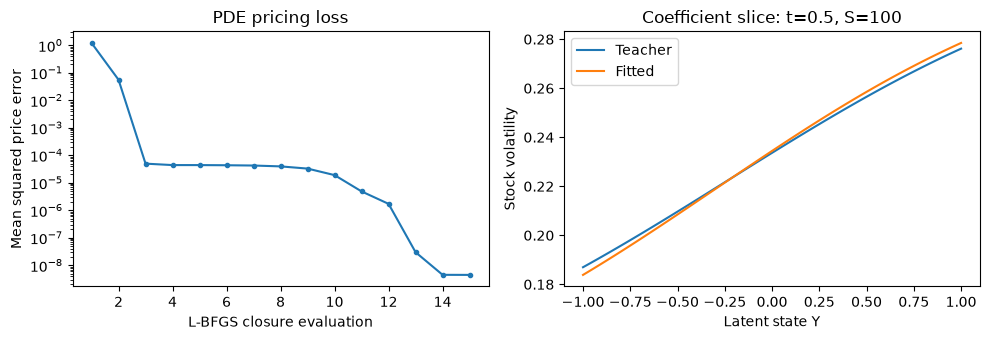

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].semilogy(range(1, len(history)+1), history, marker=".")
axs[0].set(xlabel="L-BFGS closure evaluation", ylabel="Mean squared price error", title="PDE pricing loss")
y_values = torch.linspace(-1., 1., 100, dtype=DTYPE)
slice_features = torch.stack((torch.full_like(y_values, .5), torch.zeros_like(y_values), y_values), -1)
with torch.no_grad():
    for model, label in ((teacher, "Teacher"), (student, "Fitted")):
        _, factor = model(slice_features)
        axs[1].plot(y_values, factor[..., 0, 0], label=label)
axs[1].set(xlabel="Latent state Y", ylabel="Stock volatility", title="Coefficient slice: t=0.5, S=100")
axs[1].legend()
fig.tight_layout()
plt.show()
RESULT = {"initial_rmse": initial_loss.item()**.5, "final_rmse": final_loss**.5,
          "network_gradient_norm": first_grad_norm, "output_bias_gradients": output_grad.tolist(),
          "closure_evaluations": len(history), "target_prices": target_prices.tolist(),
          "fitted_prices": fitted_prices.tolist()}

Three prices cannot identify every network weight or the complete latent
dynamics. The recovered coefficient slice may differ from the teacher despite a
small pricing loss. Both models use the same modest 21 × 9 mesh and 12 rollback
steps; refinement and domain tests are needed to assess pricing accuracy.

This demonstration trains on synthetic risk-neutral prices only. It establishes
the gradient path from a price loss through the PDE to neural drift and diffusion
parameters. Historical dynamics, a P/Q change-of-measure model, out-of-sample
prediction and unique identification are outside its scope.